# Case Study: Auto MPG Data Analysis with NumPy, Pandas and Matplotlib
**ICT Academy of Kerala · AI/ML Batch · Python for Data Analysis**

**Student version.** Write your code in the empty cells under each question.

## About the dataset
`auto-mpg.csv` contains the specifications and fuel efficiency of **398 cars** (model years 1970 to 1982).

| Column | Meaning |
|---|---|
| `mpg` | miles per gallon (fuel efficiency) |
| `cylinders` | number of engine cylinders |
| `displacement` | engine size |
| `horsepower` | engine power |
| `weight` | weight of the car (lb) |
| `acceleration` | time to accelerate (seconds; a **smaller** number means faster) |
| `model_year` | year of the model, **stored as two digits** (70 means 1970) |
| `origin` | 1 = USA, 2 = Europe, 3 = Japan |
| `car_name` | name of the car |

## Read this first
- **Keep `auto-mpg.csv` in the same folder as this notebook.** In Google Colab upload it using the **Files** panel on the left.
- The file uses **`?`** for missing horsepower values. The setup cell below reads these as `NaN` (missing).
- The setup cell also renames `car name` to `car_name` and `model year` to `model_year`, as used in the questions.
- Work through the tasks **in order from the top**: some later tasks use variables from earlier ones, and Pandas Question P3 fills the missing horsepower values in `df`.
- Part A (N1 to N10) uses **NumPy**, Part B (P1 to P10) uses **Pandas**, Part C (M1 to M10) uses **Matplotlib**.
- Under each task, click **"Check your answer"** only **after** you have tried. Your values must match.
- Finish with **Kernel → Restart and Run All** and check that there are no errors.

## Setup: run this cell first

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset. The file marks missing horsepower with "?", so we tell pandas to read it as missing (NaN).
df = pd.read_csv("/content/sample_data/auto-mpg.csv", na_values="?")

# Use column names without spaces (car name -> car_name, model year -> model_year)
df.columns = df.columns.str.replace(" ", "_")

print(df.shape)
print(df.columns.tolist())

(398, 9)
['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']


---
# Part A · NumPy Problems

### N1 · Basic Array Operations
Convert the `mpg` column into a NumPy array and calculate:
- the **mean, median and standard deviation** of `mpg`
- the **number of cars** with `mpg` greater than 25

<details>
<summary>✅ Check your answer (expected output)</summary>

```
Mean: 23.51
Median: 23.0
Std: 7.81
Cars with mpg > 25: 158
```

</details>

In [73]:
# Write your code here
mean=round(np.mean(df['mpg']),2)
print("Mean:",mean)
median=round(np.median(df['mpg']),2)
print("Median:",median)
std=round(np.std(df['mpg']),2)
print("Std:",std)
cars=np.sum(df['mpg']>25)
print("Cars with mpg > 25:",cars)

Mean: 23.51
Median: 23.0
Std: 7.81
Cars with mpg > 25: 158


### N2 · Filtering
Using NumPy, filter all cars with **more than 6 cylinders**. Return the corresponding `car_name` as a list. (Print how many cars there are and the first 5 names.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
103
['chevrolet chevelle malibu', 'buick skylark 320', 'plymouth satellite', 'amc rebel sst', 'ford torino']
```

</details>

In [74]:
# Write your code here
name=df['car_name'][df['cylinders']>6]
print(len(name))
print(name[:5].to_list())


103
['chevrolet chevelle malibu', 'buick skylark 320', 'plymouth satellite', 'amc rebel sst', 'ford torino']


### N3 · Statistical Analysis
Compute the **25th, 50th and 75th percentiles** of the `weight` column using NumPy.

<details>
<summary>✅ Check your answer (expected output)</summary>

```
[2223.75 2803.5  3608.  ]
```

</details>

In [75]:
# Write your code here
print(np.percentile(df['weight'],[25,50,75]))


[2223.75 2803.5  3608.  ]


### N4 · Array Manipulation
Convert the `acceleration` column into a NumPy array and **normalise** its values (scale between 0 and 1). (Print the smallest and largest value after scaling, and the first 5 scaled values with 3 decimals.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
0.0 1.0
[0.238 0.208 0.179 0.238 0.149]
```

</details>

In [76]:
# Write your code here
acc=np.array(df['acceleration'])
acc_norm=((acc-acc.min())/(acc.max()-acc.min())).round(3)
print(f"{acc_norm.min()} {acc_norm.max()}")
print(acc_norm[:5])
#print(round( (acc-acc.min())/(acc.max()-acc.min()),3))

0.0 1.0
[0.238 0.208 0.179 0.238 0.149]


### N5 · Broadcasting
Increase all `horsepower` values by **10%** and store the updated values in a **new** NumPy array. Handle missing data (if any) by replacing it with the **mean of the column** before applying the increase. (Print the number of missing values found, the mean used with 2 decimals, and the first 5 new values with 2 decimals.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
Missing: 6
Mean used: 104.47
[143.  181.5 165.  165.  154. ]
```

</details>

In [77]:
# Write your code here
hp=df['horsepower'].to_numpy()
print(f"Missing: {np.isnan(hp).sum()}")
hp_mean=round(np.nanmean(hp),2)
print(f'Mean used: {hp_mean}')

Missing: 6
Mean used: 104.47


### N6 · Boolean Indexing
Find the **average `displacement`** of cars with an `origin` of 2 (Europe) using NumPy indexing. (Print it with 2 decimals.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
109.14
```

</details>

In [78]:
# Write your code here
disp_arr = df['displacement'].to_numpy()
origin_arr = df['origin'].to_numpy()
europe_disp = disp_arr[origin_arr == 2]
print(f"{np.mean(europe_disp):.2f}")

109.14


### N7 · Matrix Operations
Create a 2-D NumPy array containing the columns `mpg`, `horsepower` and `weight`. Compute the **dot product** of this matrix with the vector `[1, 0.5, -0.2]`. (Use the horsepower with the missing values already replaced, from Question N5. Print the shape of the matrix, the shape of the result and the first 5 results with 2 decimals.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
(398, 3) (398,)
[-617.8 -641.1 -594.2 -595.6 -602.8]
```

</details>

In [79]:
# Write your code here
hp_clean = np.where(df['horsepower'].isna(), df['horsepower'].mean(), df['horsepower'])
mat = np.column_stack((df['mpg'].to_numpy(), hp_clean, df['weight'].to_numpy()))
vec = np.array([1, 0.5, -0.2])

result = np.dot(mat, vec)
print(mat.shape, result.shape)
print(result[:5].round(2))

(398, 3) (398,)
[-617.8 -641.1 -594.2 -595.6 -602.8]


### N8 · Sorting
Use NumPy to sort the cars by `model_year` in **descending** order and display the **first five car names**. (Use a stable sort so cars with the same year keep their original order.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
['chevrolet cavalier' 'chevrolet cavalier wagon'
 'chevrolet cavalier 2-door' 'pontiac j2000 se hatchback' 'dodge aries se']
```

</details>

In [80]:
# Write your code here
years = df['model_year'].to_numpy()
names = df['car_name'].to_numpy()

sorted_indices = np.argsort(-years, kind='stable')
print(names[sorted_indices][:5])

['chevrolet cavalier' 'chevrolet cavalier wagon'
 'chevrolet cavalier 2-door' 'pontiac j2000 se hatchback' 'dodge aries se']


### N9 · Correlation
Compute the **Pearson correlation coefficient** between `mpg` and `weight` using NumPy. (Print it with 4 decimals.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
-0.8317
```

</details>

In [81]:
# Write your code here
corr = np.corrcoef(df['mpg'].to_numpy(), df['weight'].to_numpy())[0, 1]
print(f"{corr:.4f}")

-0.8317


### N10 · Conditional Aggregates
Calculate the **mean `mpg`** for cars grouped by the number of `cylinders` using NumPy techniques. (Print one line per cylinder count, mean with 2 decimals.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
3 20.55
4 29.29
5 27.37
6 19.99
8 14.96
```

</details>

In [82]:
# Write your code here
cyls = np.unique(df['cylinders'].to_numpy())
for c in sorted(cyls):
    mean_mpg = df['mpg'].to_numpy()[df['cylinders'].to_numpy() == c].mean()
    print(f"{int(c)} {mean_mpg:.2f}")

3 20.55
4 29.29
5 27.37
6 19.99
8 14.96


---
# Part B · Pandas Problems

### P1 · Basic Exploration
Load the dataset into a Pandas DataFrame (already done in the setup cell: use `df`). Display:
- the **first 10 rows**
- the **total number of rows and columns**
- **summary statistics** for the numerical columns

<details>
<summary>✅ Check your answer (expected output)</summary>

```
    mpg  cylinders  displacement  ...  model_year  origin                   car_name
0  18.0          8         307.0  ...          70       1  chevrolet chevelle malibu
1  15.0          8         350.0  ...          70       1          buick skylark 320
2  18.0          8         318.0  ...          70       1         plymouth satellite
3  16.0          8         304.0  ...          70       1              amc rebel sst
4  17.0          8         302.0  ...          70       1                ford torino
5  15.0          8         429.0  ...          70       1           ford galaxie 500
6  14.0          8         454.0  ...          70       1           chevrolet impala
7  14.0          8         440.0  ...          70       1          plymouth fury iii
8  14.0          8         455.0  ...          70       1           pontiac catalina
9  15.0          8         390.0  ...          70       1         amc ambassador dpl

[10 rows x 9 columns]
(398, 9)
              mpg   cylinders  ...  model_year      origin
count  398.000000  398.000000  ...  398.000000  398.000000
mean    23.514573    5.454774  ...   76.010050    1.572864
std      7.815984    1.701004  ...    3.697627    0.802055
min      9.000000    3.000000  ...   70.000000    1.000000
25%     17.500000    4.000000  ...   73.000000    1.000000
50%     23.000000    4.000000  ...   76.000000    1.000000
75%     29.000000    8.000000  ...   79.000000    2.000000
max     46.600000    8.000000  ...   82.000000    3.000000

[8 rows x 8 columns]
```

</details>

In [83]:
# Write your code here
print(df.head(10))
print(df.shape)
print(df.describe())

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   
5  15.0          8         429.0       198.0    4341          10.0   
6  14.0          8         454.0       220.0    4354           9.0   
7  14.0          8         440.0       215.0    4312           8.5   
8  14.0          8         455.0       225.0    4425          10.0   
9  15.0          8         390.0       190.0    3850           8.5   

   model_year  origin                   car_name  
0          70       1  chevrolet chevelle malibu  
1          70       1          buick skylark 320  
2          70       1         plymouth satellite  
3          70       1    

### P2 · Filtering and Indexing
Find all cars manufactured in **1975** with a `weight` less than **3000**. Return the DataFrame with the selected columns `car_name`, `weight` and `mpg`. (In this file the year is stored as two digits: 75 means 1975. Print the number of cars and the first 5 rows.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
14
           car_name  weight   mpg
167  toyota corolla    2171  29.0
168      ford pinto    2639  23.0
169     amc gremlin    2914  20.0
170   pontiac astro    2592  23.0
171   toyota corona    2702  24.0
```

</details>

In [84]:
# Write your code here
filtered = df[(df['model_year'] == 75) & (df['weight'] < 3000)]
print(len(filtered))
print(filtered[['car_name', 'weight', 'mpg']].head(5))

14
           car_name  weight   mpg
167  toyota corolla    2171  29.0
168      ford pinto    2639  23.0
169     amc gremlin    2914  20.0
170   pontiac astro    2592  23.0
171   toyota corona    2702  24.0


### P3 · Handling Missing Data
**Identify** if there are any missing values in the dataset. **Replace** the missing values in the `horsepower` column with the column's **median**. (Print the missing values per column before, the median used, and the number of missing values left.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64
Median: 93.5
Missing left: 0
```

</details>

In [85]:
# Write your code here
print(df.isnull().sum())
hp_median = df['horsepower'].median()
df['horsepower'].fillna(hp_median, inplace=True)

print(f"Median: {hp_median}")
print(f"Missing left: {df['horsepower'].isnull().sum()}")

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64
Median: 93.5
Missing left: 0


/tmp/ipykernel_1840/2005818153.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['horsepower'].fillna(hp_median, inplace=True)


### P4 · Data Transformation
Add a new column `power_to_weight_ratio`, calculated as `horsepower / weight`. (Print the first 5 values of the new column rounded to 5 decimals.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
0    0.03710
1    0.04468
2    0.04366
3    0.04369
4    0.04059
Name: power_to_weight_ratio, dtype: float64
```

</details>

In [86]:
# Write your code here
df['power_to_weight_ratio'] = df['horsepower'] / df['weight']
print(df['power_to_weight_ratio'].head(5).round(5))

0    0.03710
1    0.04468
2    0.04366
3    0.04369
4    0.04059
Name: power_to_weight_ratio, dtype: float64


### P5 · Group By
Group the cars by `origin` and calculate the **mean `mpg`** for each group. (Origin 1 = USA, 2 = Europe, 3 = Japan. Round to 2 decimals.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
origin
1    20.08
2    27.89
3    30.45
Name: mpg, dtype: float64
```

</details>

In [87]:
# Write your code here
print(df.groupby('origin')['mpg'].mean().round(2))

origin
1    20.08
2    27.89
3    30.45
Name: mpg, dtype: float64


### P6 · Sorting
Sort the DataFrame by `mpg` in **descending** order and display the **top 10 cars** with the highest `mpg`. (Show `car_name` and `mpg`.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
                            car_name   mpg
322                        mazda glc  46.6
329              honda civic 1500 gl  44.6
325             vw rabbit c (diesel)  44.3
394                        vw pickup  44.0
326               vw dasher (diesel)  43.4
244  volkswagen rabbit custom diesel  43.1
309                        vw rabbit  41.5
330             renault lecar deluxe  40.9
324                       datsun 210  40.8
247                   datsun b210 gx  39.4
```

</details>

In [88]:
# Write your code here
sorted_df = df.sort_values(by='mpg', ascending=False)
print(sorted_df[['car_name', 'mpg']].head(10))

                            car_name   mpg
322                        mazda glc  46.6
329              honda civic 1500 gl  44.6
325             vw rabbit c (diesel)  44.3
394                        vw pickup  44.0
326               vw dasher (diesel)  43.4
244  volkswagen rabbit custom diesel  43.1
309                        vw rabbit  41.5
330             renault lecar deluxe  40.9
324                       datsun 210  40.8
247                   datsun b210 gx  39.4


### P7 · Apply Function
Create a new column `performance_score` using this custom function, applied to **each row**, and store the result in the new column.

```python
def performance_score(row):
    return row['mpg'] * row['acceleration'] / row['weight']
```
(Print the first 5 values of the new column rounded to 5 decimals.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
0    0.06164
1    0.04671
2    0.05763
3    0.05593
4    0.05175
Name: performance_score, dtype: float64
```

</details>

In [89]:
# Write your code here
def performance_score(row):
    return row['mpg'] * row['acceleration'] / row['weight']

df['performance_score'] = df.apply(performance_score, axis=1)
print(df['performance_score'].head(5).round(5))

0    0.06164
1    0.04671
2    0.05763
3    0.05593
4    0.05175
Name: performance_score, dtype: float64


### P8 · Visualization Preparation
Generate a **summary DataFrame** with the average `mpg`, `weight` and `horsepower` for each `model_year`. (Round to 2 decimals and print the first 5 rows.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
              mpg   weight  horsepower
model_year                            
70          17.69  3372.79      147.83
71          21.25  2995.43      106.55
72          18.71  3237.71      120.18
73          17.10  3419.02      130.48
74          22.70  2877.93       94.20
```

</details>

In [90]:
# Write your code here
summary_df = df.groupby('model_year')[['mpg', 'weight', 'horsepower']].mean().round(2)
print(summary_df.head(5))

              mpg   weight  horsepower
model_year                            
70          17.69  3372.79      147.83
71          21.25  2995.43      106.55
72          18.71  3237.71      120.18
73          17.10  3419.02      130.48
74          22.70  2877.93       94.20


### P9 · Exporting Data
Save a subset of the data containing only `mpg`, `cylinders`, `horsepower` and `weight` for cars with **mpg > 30** into a CSV file named `high_mpg_cars.csv`. (Do not save the row numbers. Then load the file again and print its shape and its first 3 rows.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
(85, 4)
    mpg  cylinders  horsepower  weight
0  31.0          4        65.0    1773
1  35.0          4        69.0    1613
2  31.0          4        67.0    1950
```

</details>

In [91]:
# Write your code here
subset = df[df['mpg'] > 30][['mpg', 'cylinders', 'horsepower', 'weight']]
subset.to_csv('high_mpg_cars.csv', index=False)

loaded = pd.read_csv('high_mpg_cars.csv')
print(loaded.shape)
print(loaded.head(3))

(85, 4)
    mpg  cylinders  horsepower  weight
0  31.0          4        65.0    1773
1  35.0          4        69.0    1613
2  31.0          4        67.0    1950


### P10 · Finding Anomalies
Identify potential **outliers** in the `mpg` column using the **Interquartile Range (IQR)** method:
- Calculate the IQR for `mpg`.
- Define outliers as values less than `Q1 - 1.5 * IQR` or greater than `Q3 + 1.5 * IQR`.
- Create a DataFrame of cars classified as outliers, displaying `car_name`, `mpg` and `model_year`.

(Print Q1, Q3, IQR, the two limits, and the outlier DataFrame.)

<details>
<summary>✅ Check your answer (expected output)</summary>

```
17.5 29.0 11.5
0.25 46.25
      car_name   mpg  model_year
322  mazda glc  46.6          80
```

</details>

In [92]:
# Write your code here
Q1 = df['mpg'].quantile(0.25)
Q3 = df['mpg'].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print(f"{Q1} {Q3} {IQR}")
print(f"{lower_limit} {upper_limit}")

outliers = df[(df['mpg'] < lower_limit) | (df['mpg'] > upper_limit)]
print(outliers[['car_name', 'mpg', 'model_year']])

17.5 29.0 11.5
0.25 46.25
      car_name   mpg  model_year
322  mazda glc  46.6          80


---
# Part C · Matplotlib Problems

### M1 · Distribution of mpg
**What is the distribution of miles per gallon (mpg) in the dataset?**
Plot a **histogram** of `mpg` values.

<details>
<summary>✅ What your chart should show</summary>

A **histogram** with 20 bars, **skewed to the right**: about 65% of the cars have mpg between 15 and 30, the tallest bars are in the low-to-mid 20s, and only a few cars go above 40 mpg (the maximum is 46.6).

</details>

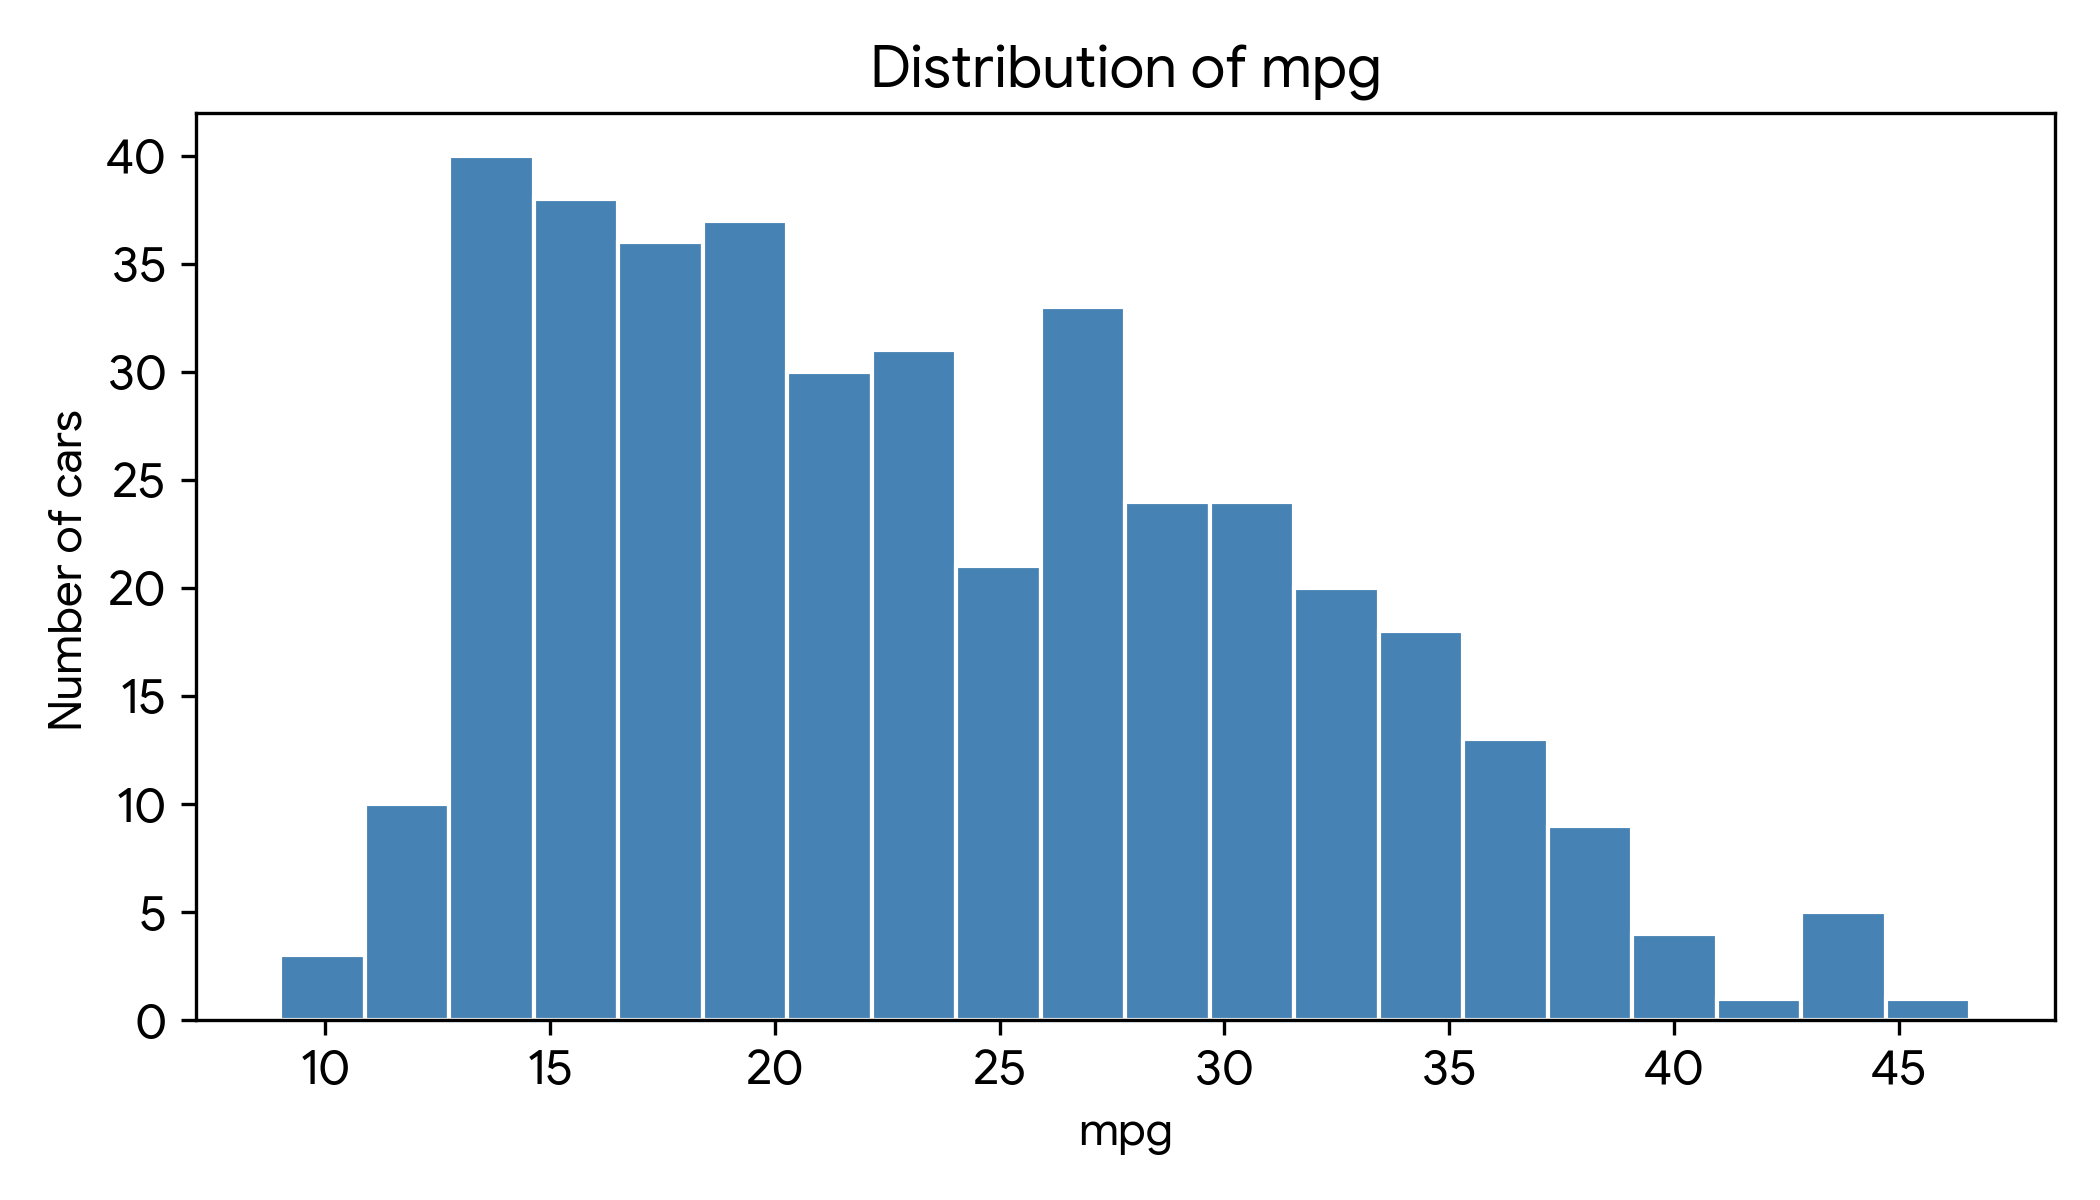

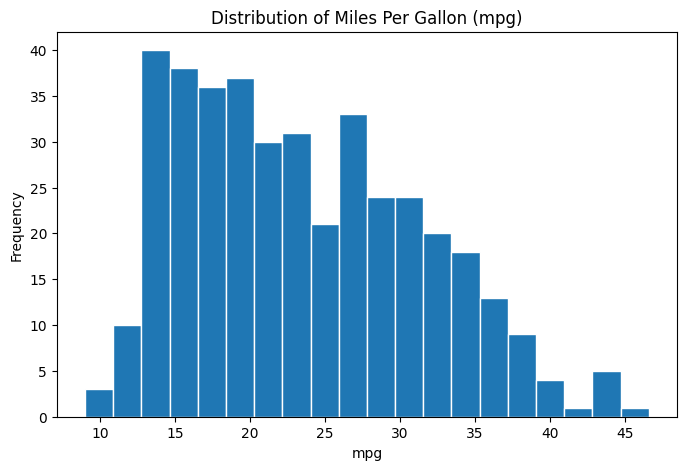

In [93]:
# Write your code here
plt.figure(figsize=(8, 5))
plt.hist(df['mpg'], bins=20, edgecolor='white')
plt.title('Distribution of Miles Per Gallon (mpg)')
plt.xlabel('mpg')
plt.ylabel('Frequency')
plt.show()

**✍️ Your observation** (write 1 or 2 lines):

*A histogram with 20 bars, skewed to the right: the tallest bars are clustered between 14 and 22 mpg, the frequency gradually tapers off toward higher values, and only a small number of cars exceed 40 mpg (reaching a maximum of 46.6).*

### M2 · mpg and cylinders
**How does `mpg` vary with the number of `cylinders`?**
Use a **boxplot** to compare `mpg` across different `cylinders`.

<details>
<summary>✅ What your chart should show</summary>

One box per cylinder count (3, 4, 5, 6, 8). **mpg falls as cylinders increase**: median mpg is about 28.2 for 4 cylinders, 19.0 for 6 and 14.0 for 8. The 3-cylinder and 5-cylinder boxes contain very few cars. 4-cylinder cars show the widest spread and some high outliers.

</details>

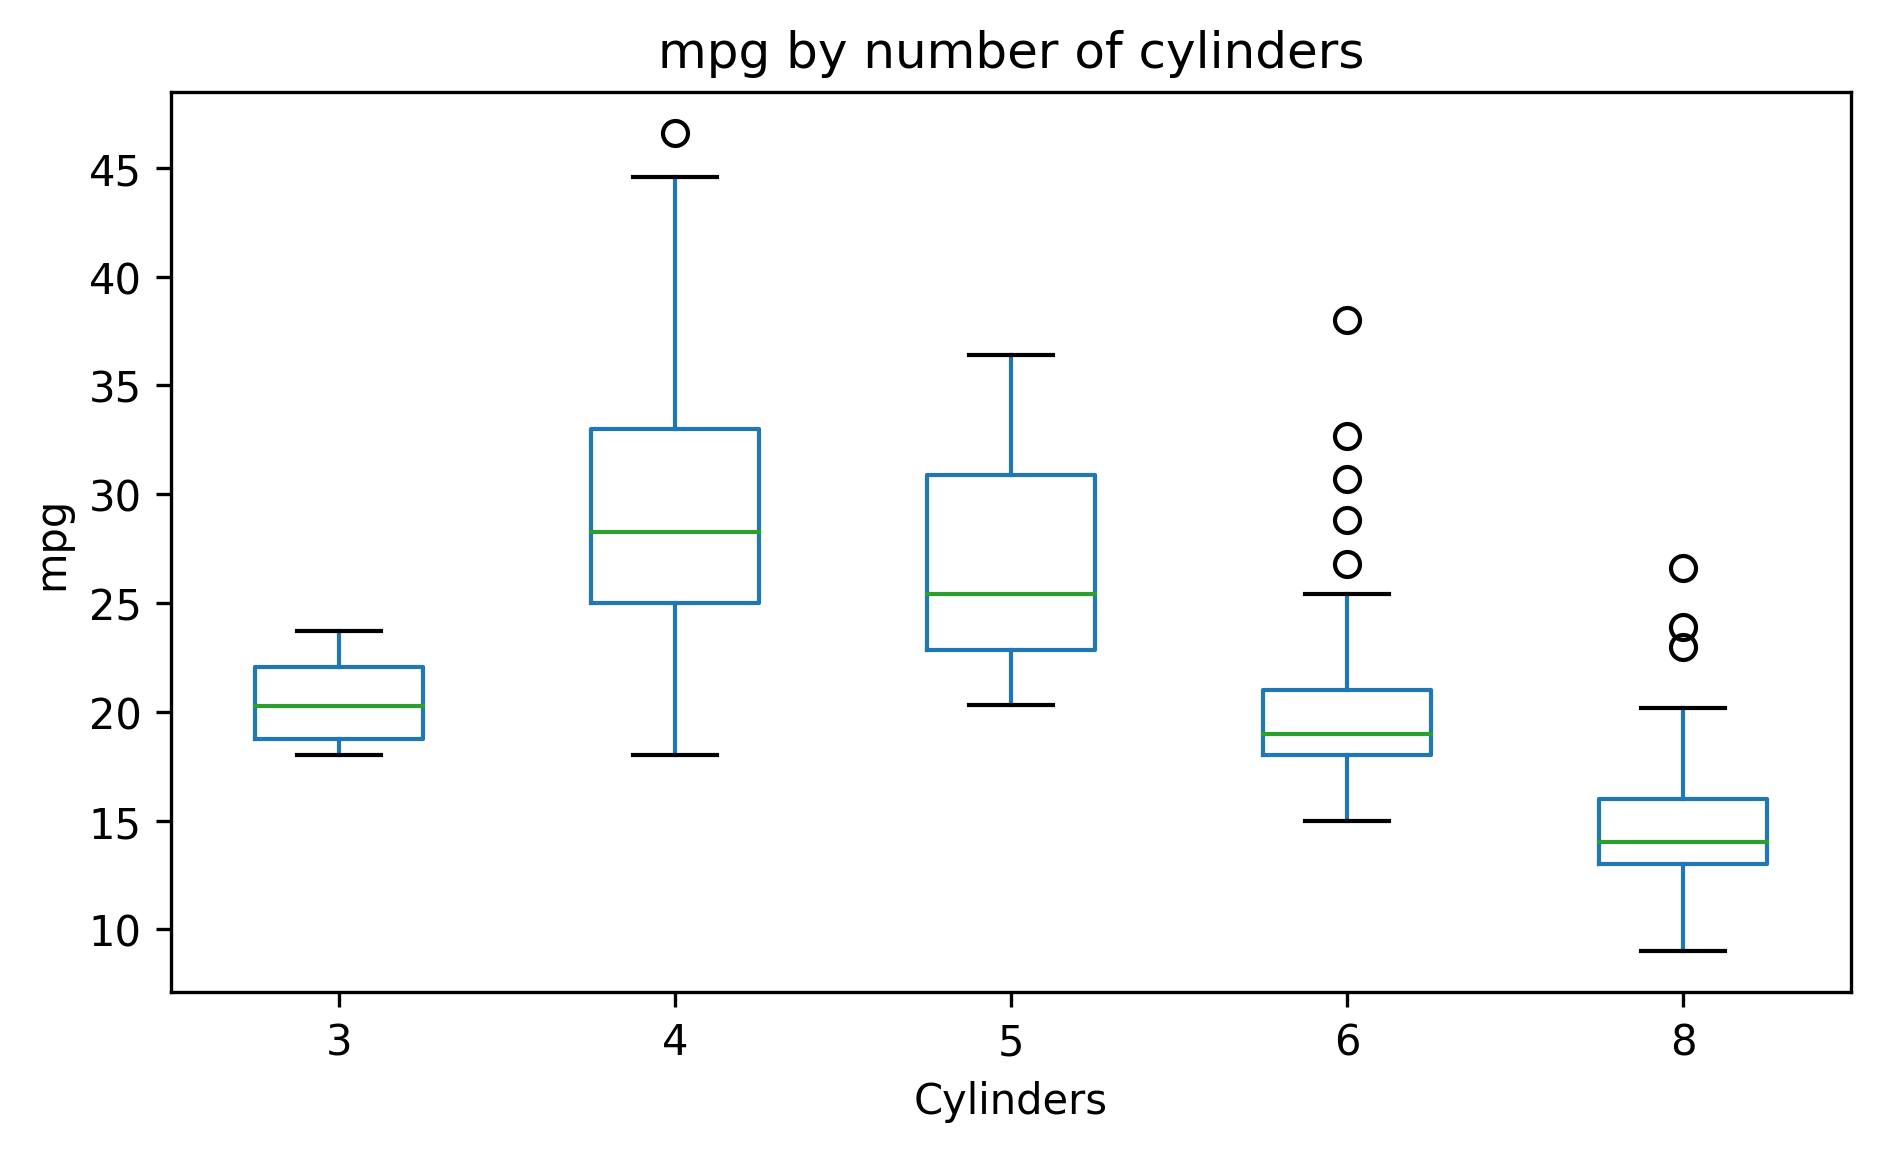

/tmp/ipykernel_1840/1894456742.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(cyl_groups, labels=sorted(df['cylinders'].unique()))


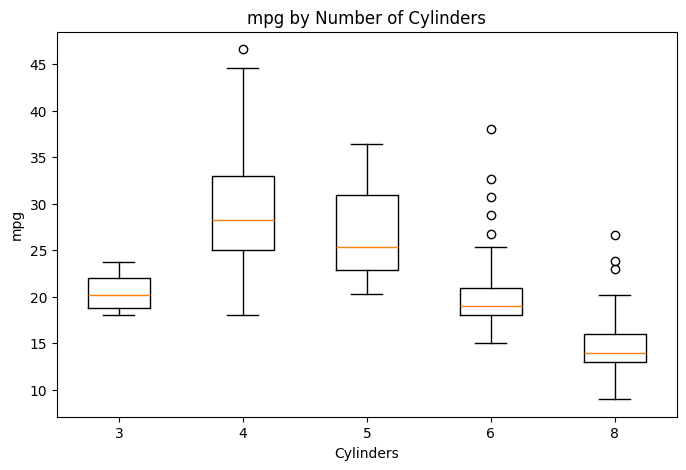

In [94]:
# Write your code here
plt.figure(figsize=(8, 5))
cyl_groups = [df[df['cylinders'] == c]['mpg'] for c in sorted(df['cylinders'].unique())]
plt.boxplot(cyl_groups, labels=sorted(df['cylinders'].unique()))
plt.title('mpg by Number of Cylinders')
plt.xlabel('Cylinders')
plt.ylabel('mpg')
plt.show()

**✍️ Your observation** (write 1 or 2 lines):

*One box per cylinder count (3, 4, 5, 6, 8). mpg falls as cylinders increase: median mpg is about 28.2 for 4 cylinders, 19.0 for 6 and 14.0 for 8. The 3-cylinder and 5-cylinder boxes contain very few cars. 4-cylinder cars show the widest spread and some high outliers.*

### M3 · horsepower and mpg
**Is there a relationship between `horsepower` and `mpg`? Summarise your observation.**
Plot a **scatter plot** of `horsepower` vs `mpg`.

<details>
<summary>✅ What your chart should show</summary>

A cloud of points sloping **downwards**: more horsepower means lower mpg. The correlation is about **-0.77** (a strong negative relationship), and the relationship is curved rather than a perfect straight line.

</details>

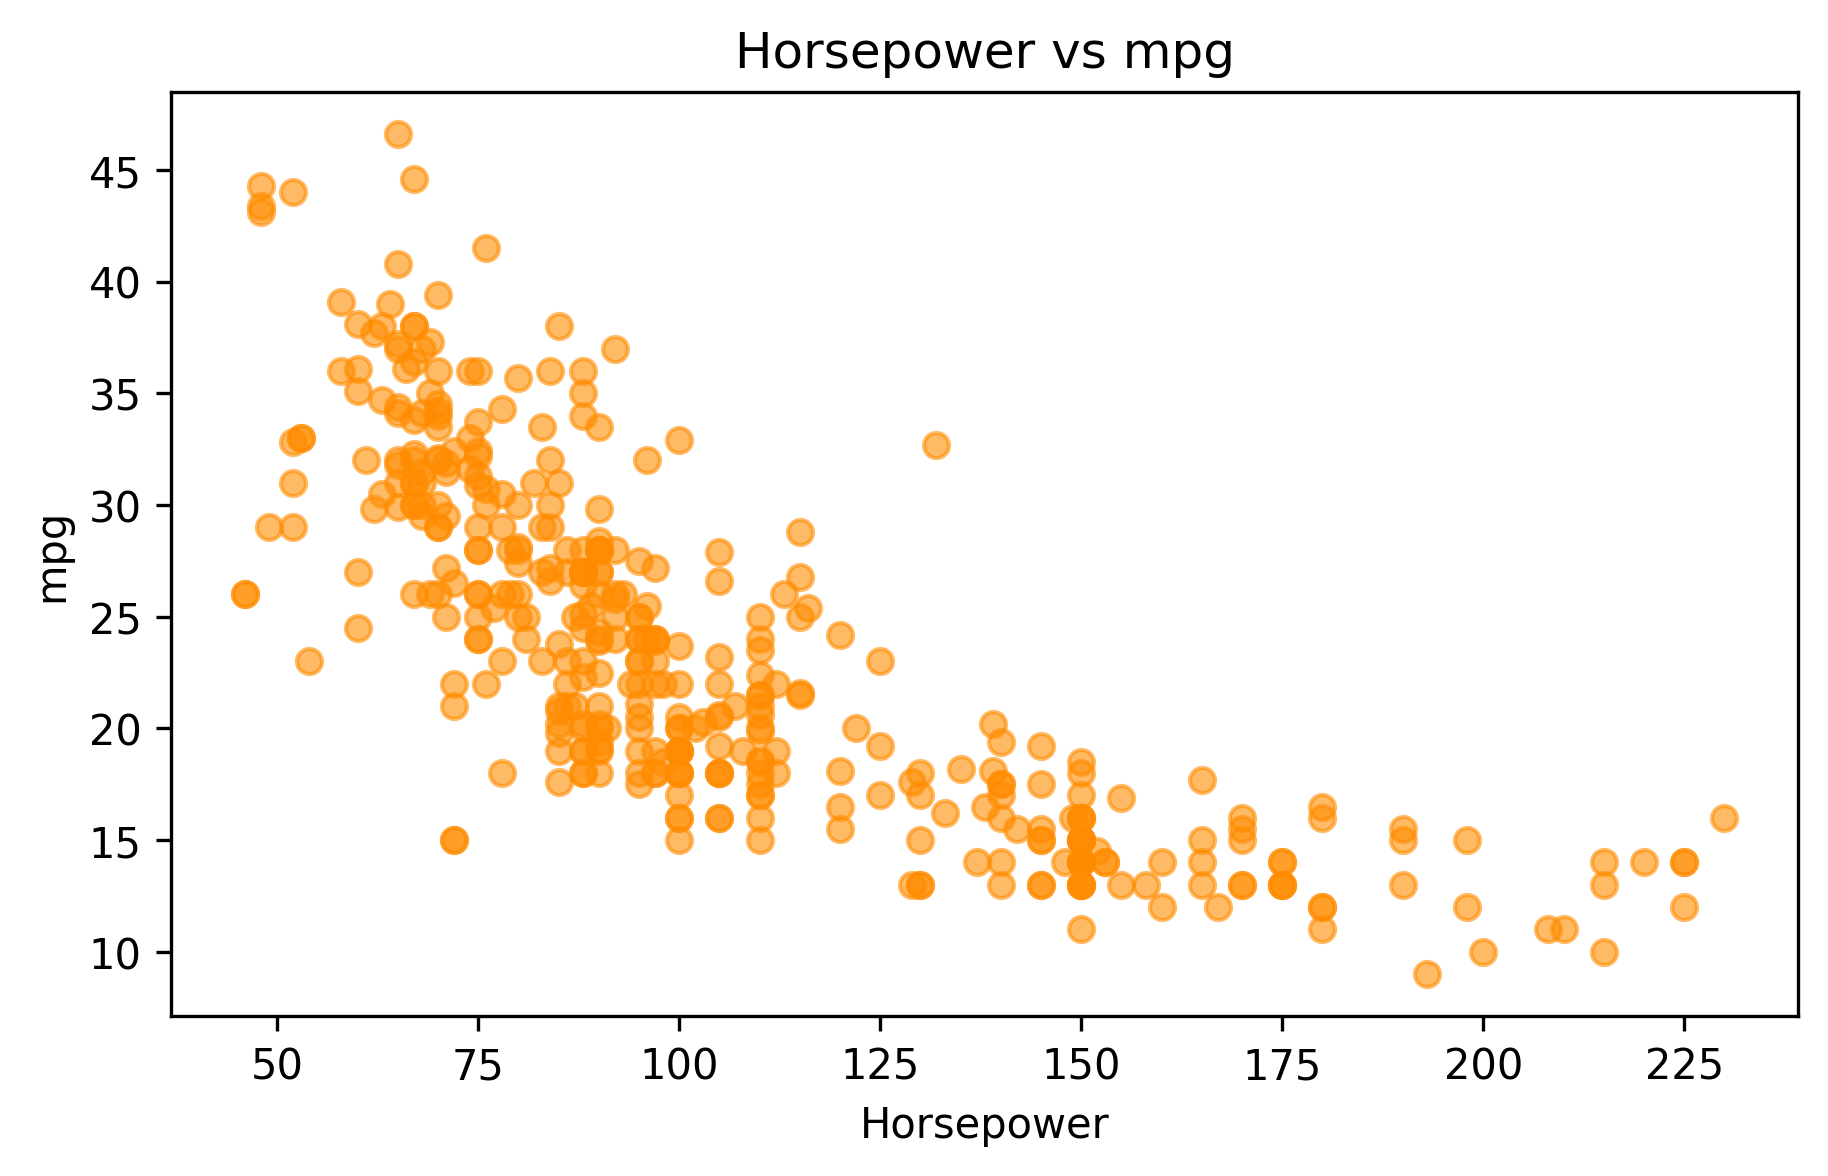

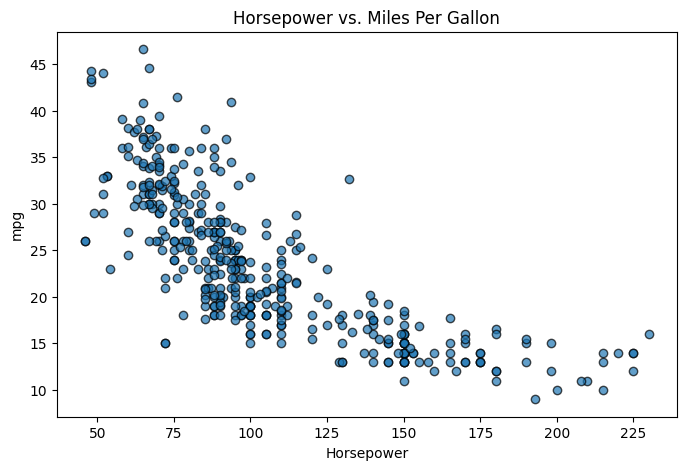

In [95]:
# Write your code here
plt.figure(figsize=(8, 5))
plt.scatter(df['horsepower'], df['mpg'], alpha=0.7, edgecolor='k')
plt.title('Horsepower vs. Miles Per Gallon')
plt.xlabel('Horsepower')
plt.ylabel('mpg')
plt.show()

**✍️ Your observation** (write 1 or 2 lines):

*A clear negative, non-linear relationship: cars with higher horsepower consistently yield significantly lower mpg, while the highest fuel efficiency is concentrated among vehicles with lower horsepower (under 100)*

### M4 · weight and mpg
**How does car `weight` influence `mpg`?**
Plot a **scatter plot with a trend line** for `weight` vs `mpg`.

<details>
<summary>✅ What your chart should show</summary>

Points sloping downwards with a red trend line: **heavier cars have lower mpg**. The correlation is about **-0.83** and the slope is about **-0.0077 mpg per lb** (roughly 7.7 mpg less for every extra 1000 lb).

</details>

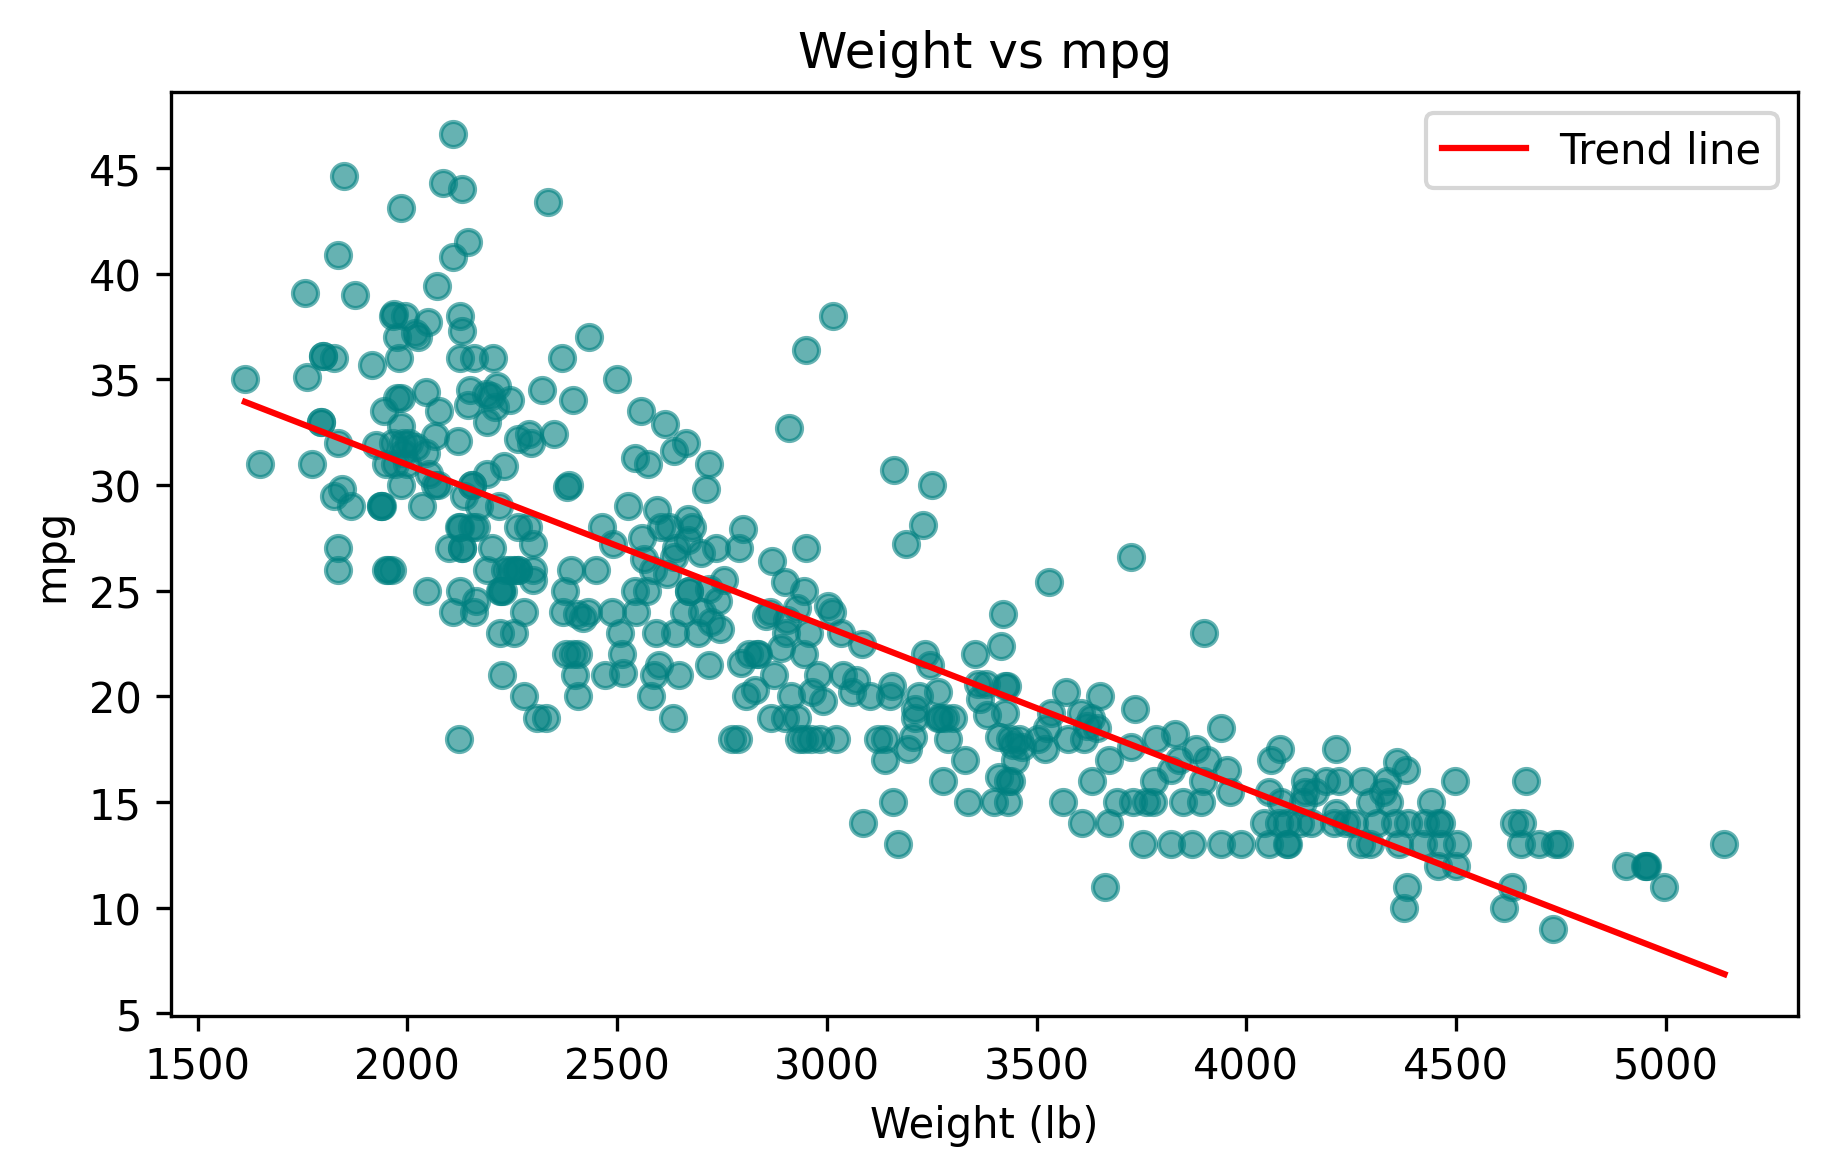

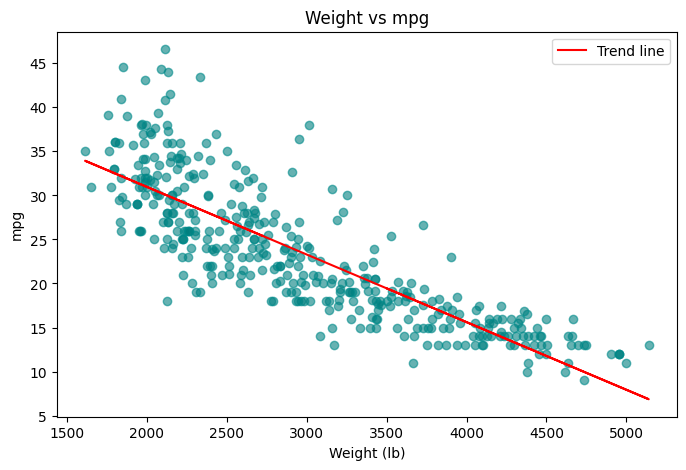

In [96]:
# Write your code here
plt.figure(figsize=(8, 5))
plt.scatter(df['weight'], df['mpg'], color='teal', alpha=0.6, edgecolor='darkcyan')
m, b = np.polyfit(df['weight'], df['mpg'], 1)
plt.plot(df['weight'], m*df['weight'] + b, color='red', label='Trend line')
plt.title('Weight vs mpg')
plt.xlabel('Weight (lb)')
plt.ylabel('mpg')
plt.legend()
plt.show()

**✍️ Your observation** (write 1 or 2 lines):

*A strong inverse correlation exists between vehicle weight and mpg; heavier cars tend to have more cylinders (8-cylinder engines cluster heavily at higher weights and lower mpg values)*

### M5 · mpg across model years
**What is the trend of average `mpg` across model years?**
Plot a **line chart** of average `mpg` per `model_year`.

<details>
<summary>✅ What your chart should show</summary>

A line that **rises over the years** with some ups and downs: average mpg goes from about 17.7 in 1970 to about 31.7 in 1982 (fuel-efficiency improved, especially after 1973 and 1979).

</details>

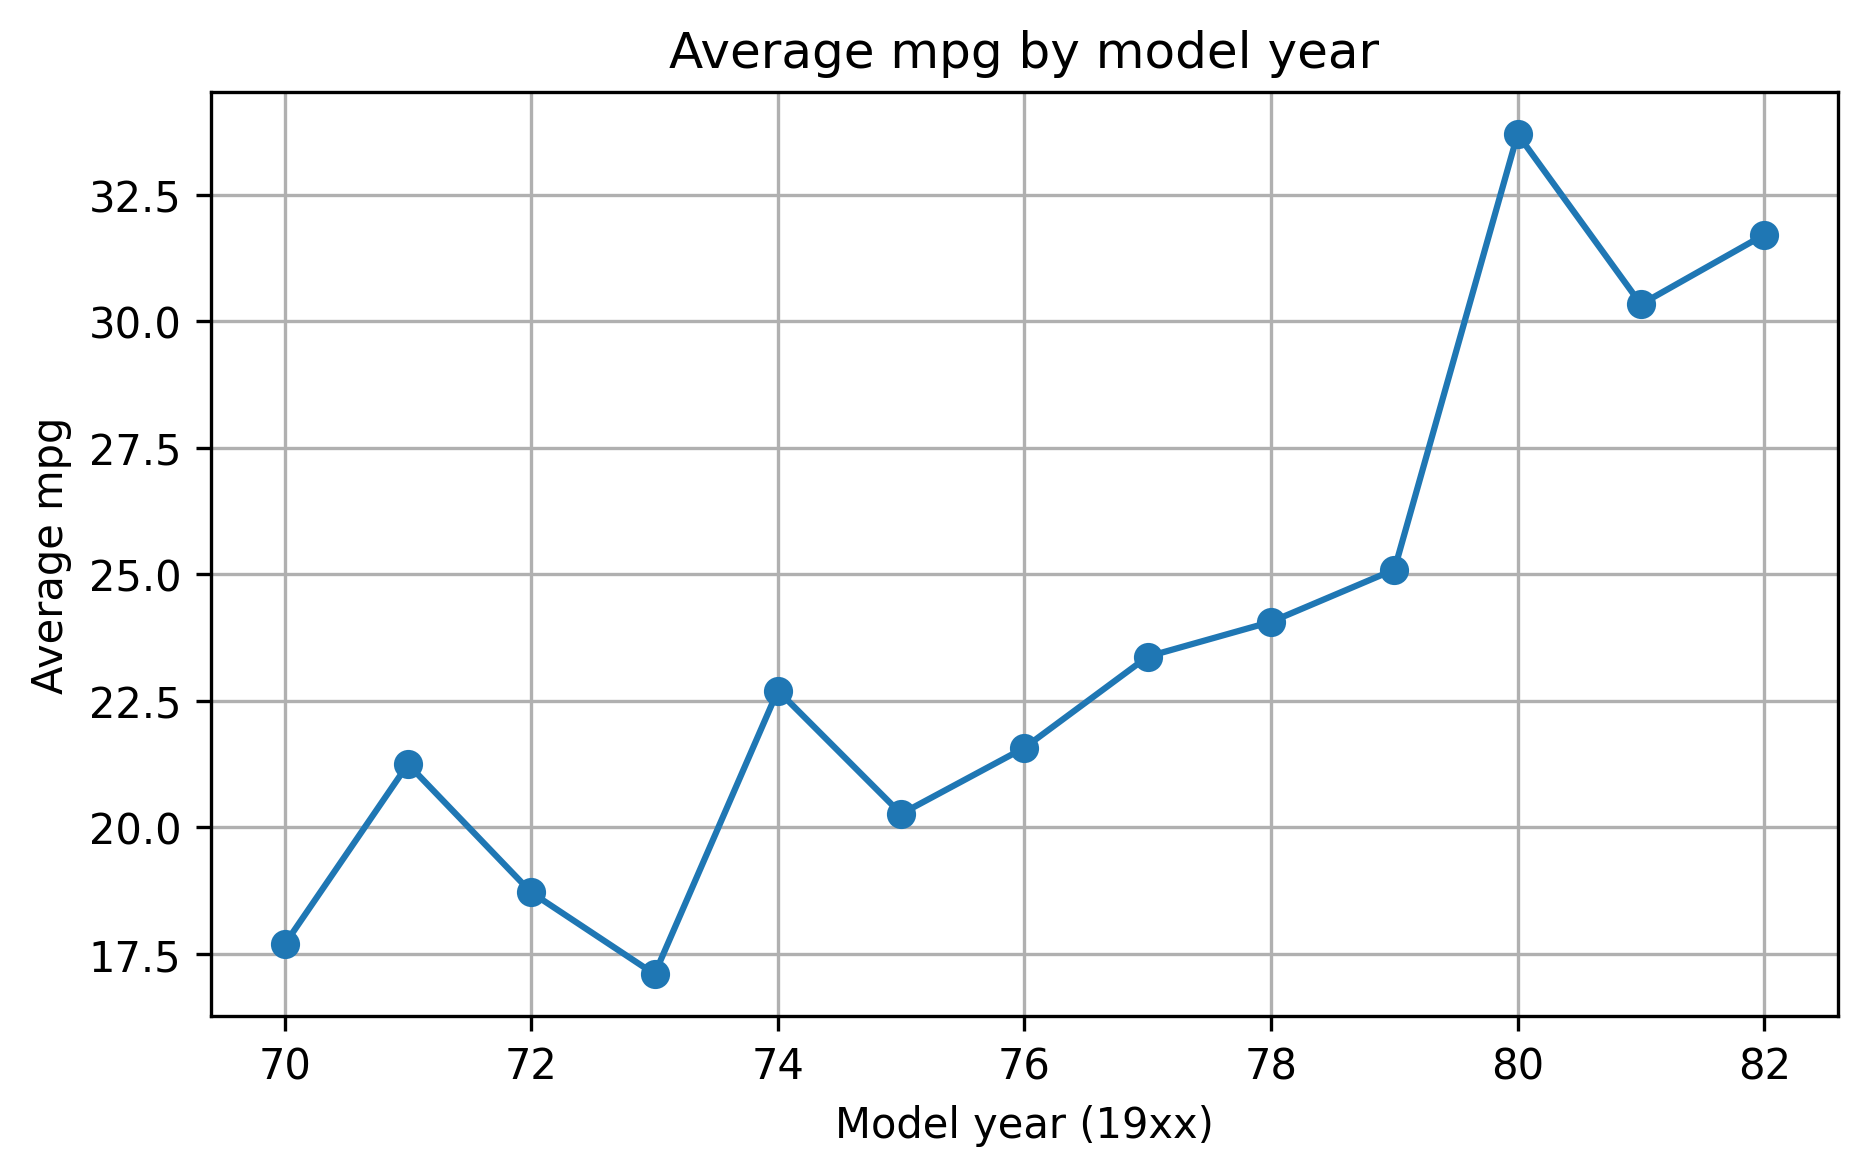

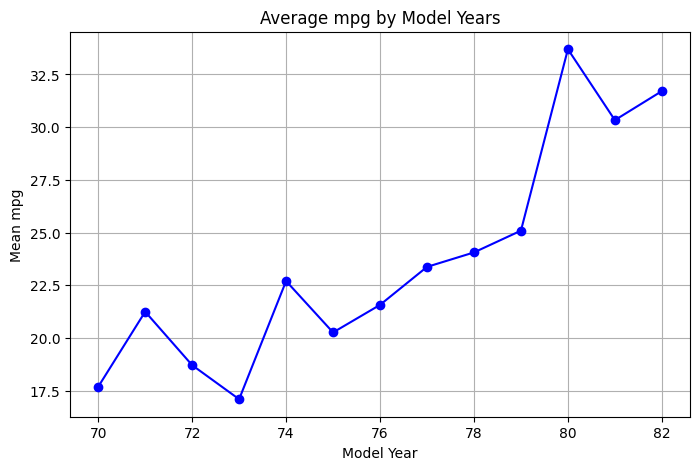

In [97]:
# Write your code here
plt.figure(figsize=(8, 5))
df.groupby('model_year')['mpg'].mean().plot(marker='o', linestyle='-', color='blue')
plt.title('Average mpg by Model Years')
plt.xlabel('Model Year')
plt.ylabel('Mean mpg')
plt.grid(True)
plt.show()

**✍️ Your observation** (write 1 or 2 lines):

*Fuel efficiency improved steadily across the years from 1970 to 1982, with mean mpg increasing from roughly 18 to over 30*

### M6 · Cars by origin
**How is the count of cars distributed by `origin`?**
Use a **bar chart** to show the number of cars for each `origin`.

<details>
<summary>✅ What your chart should show</summary>

Three bars: origin 1 (USA) = **249** cars, origin 2 (Europe) = **70**, origin 3 (Japan) = **79**. The USA bar is by far the tallest.

</details>

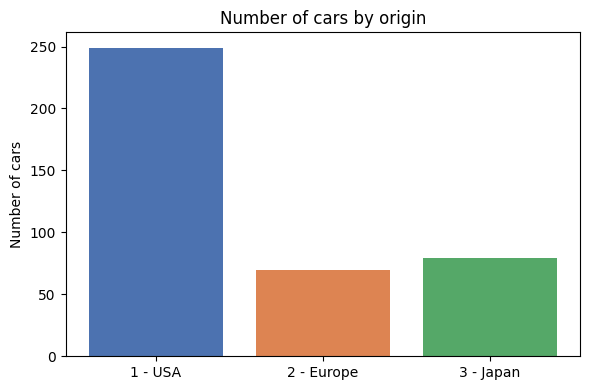

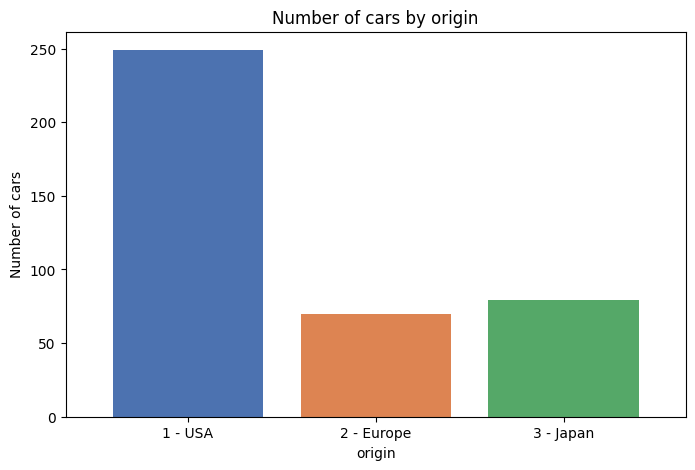

In [98]:
# Write your code here
plt.figure(figsize=(8, 5))
df['origin'].map({1: '1 - USA', 2: '2 - Europe', 3: '3 - Japan'}).value_counts()[['1 - USA', '2 - Europe', '3 - Japan']].plot(kind='bar', color=['#4c72b0', '#dd8452', '#55a868'], width=0.8, rot=0)
plt.title('Number of cars by origin')
plt.ylabel('Number of cars')
plt.show()

**✍️ Your observation** (write 1 or 2 lines):

*The distribution of acceleration times closely follows a normal, bell-shaped curve centered around 15.5 seconds, with very few extreme outliers on either end*

### M7 · acceleration and cylinders
**How do `acceleration` values vary across different `cylinders`?**
Use a **boxplot** of `acceleration` grouped by `cylinders`.

<details>
<summary>✅ What your chart should show</summary>

One box per cylinder count. Median acceleration time is about 16.2 s for 4 cylinders, 16.1 s for 6 and 13.0 s for 8: **8-cylinder cars accelerate faster on average** (smaller number) while 4-cylinder cars are slower and more spread out.

</details>

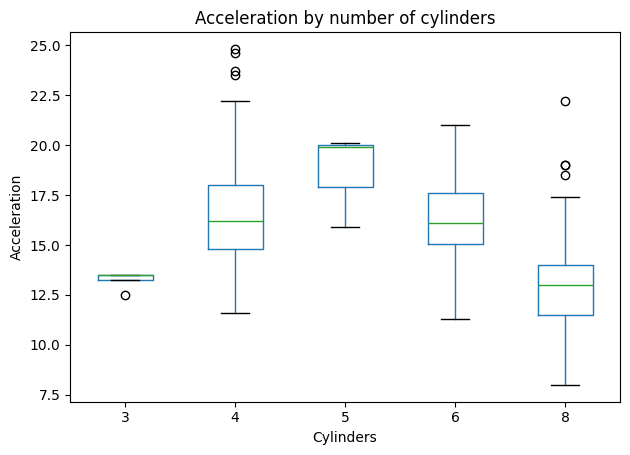

/tmp/ipykernel_1840/3604452937.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(cyl_groups, labels=sorted(df['cylinders'].unique()))


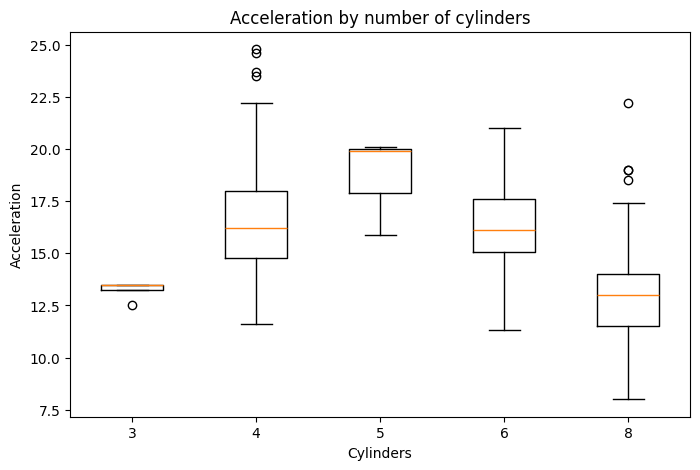

In [99]:
# Write your code here
plt.figure(figsize=(8, 5))
cyl_groups = [df[df['cylinders'] == c]['acceleration'] for c in sorted(df['cylinders'].unique())]
plt.boxplot(cyl_groups, labels=sorted(df['cylinders'].unique()))
plt.title('Acceleration by number of cylinders')
plt.xlabel('Cylinders')
plt.ylabel('Acceleration')
plt.show()

**✍️ Your observation** (write 1 or 2 lines):

*8-cylinder cars generally have the fastest acceleration (lowest times, median around 13 seconds), 4- and 6-cylinder vehicles share a similar middle range (medians near 16 seconds), and 5-cylinder cars record the slowest acceleration times (median near 20 seconds)*

### M8 · Entries by year
**Which year had the most number of car entries?**
Plot a **histogram or bar chart** of car counts by `model_year`.

<details>
<summary>✅ What your chart should show</summary>

Bars for the years 70 to 82, all between about 27 and 40 cars; **1973 is the tallest bar with 40 cars**, followed by 1978 (36).

</details>

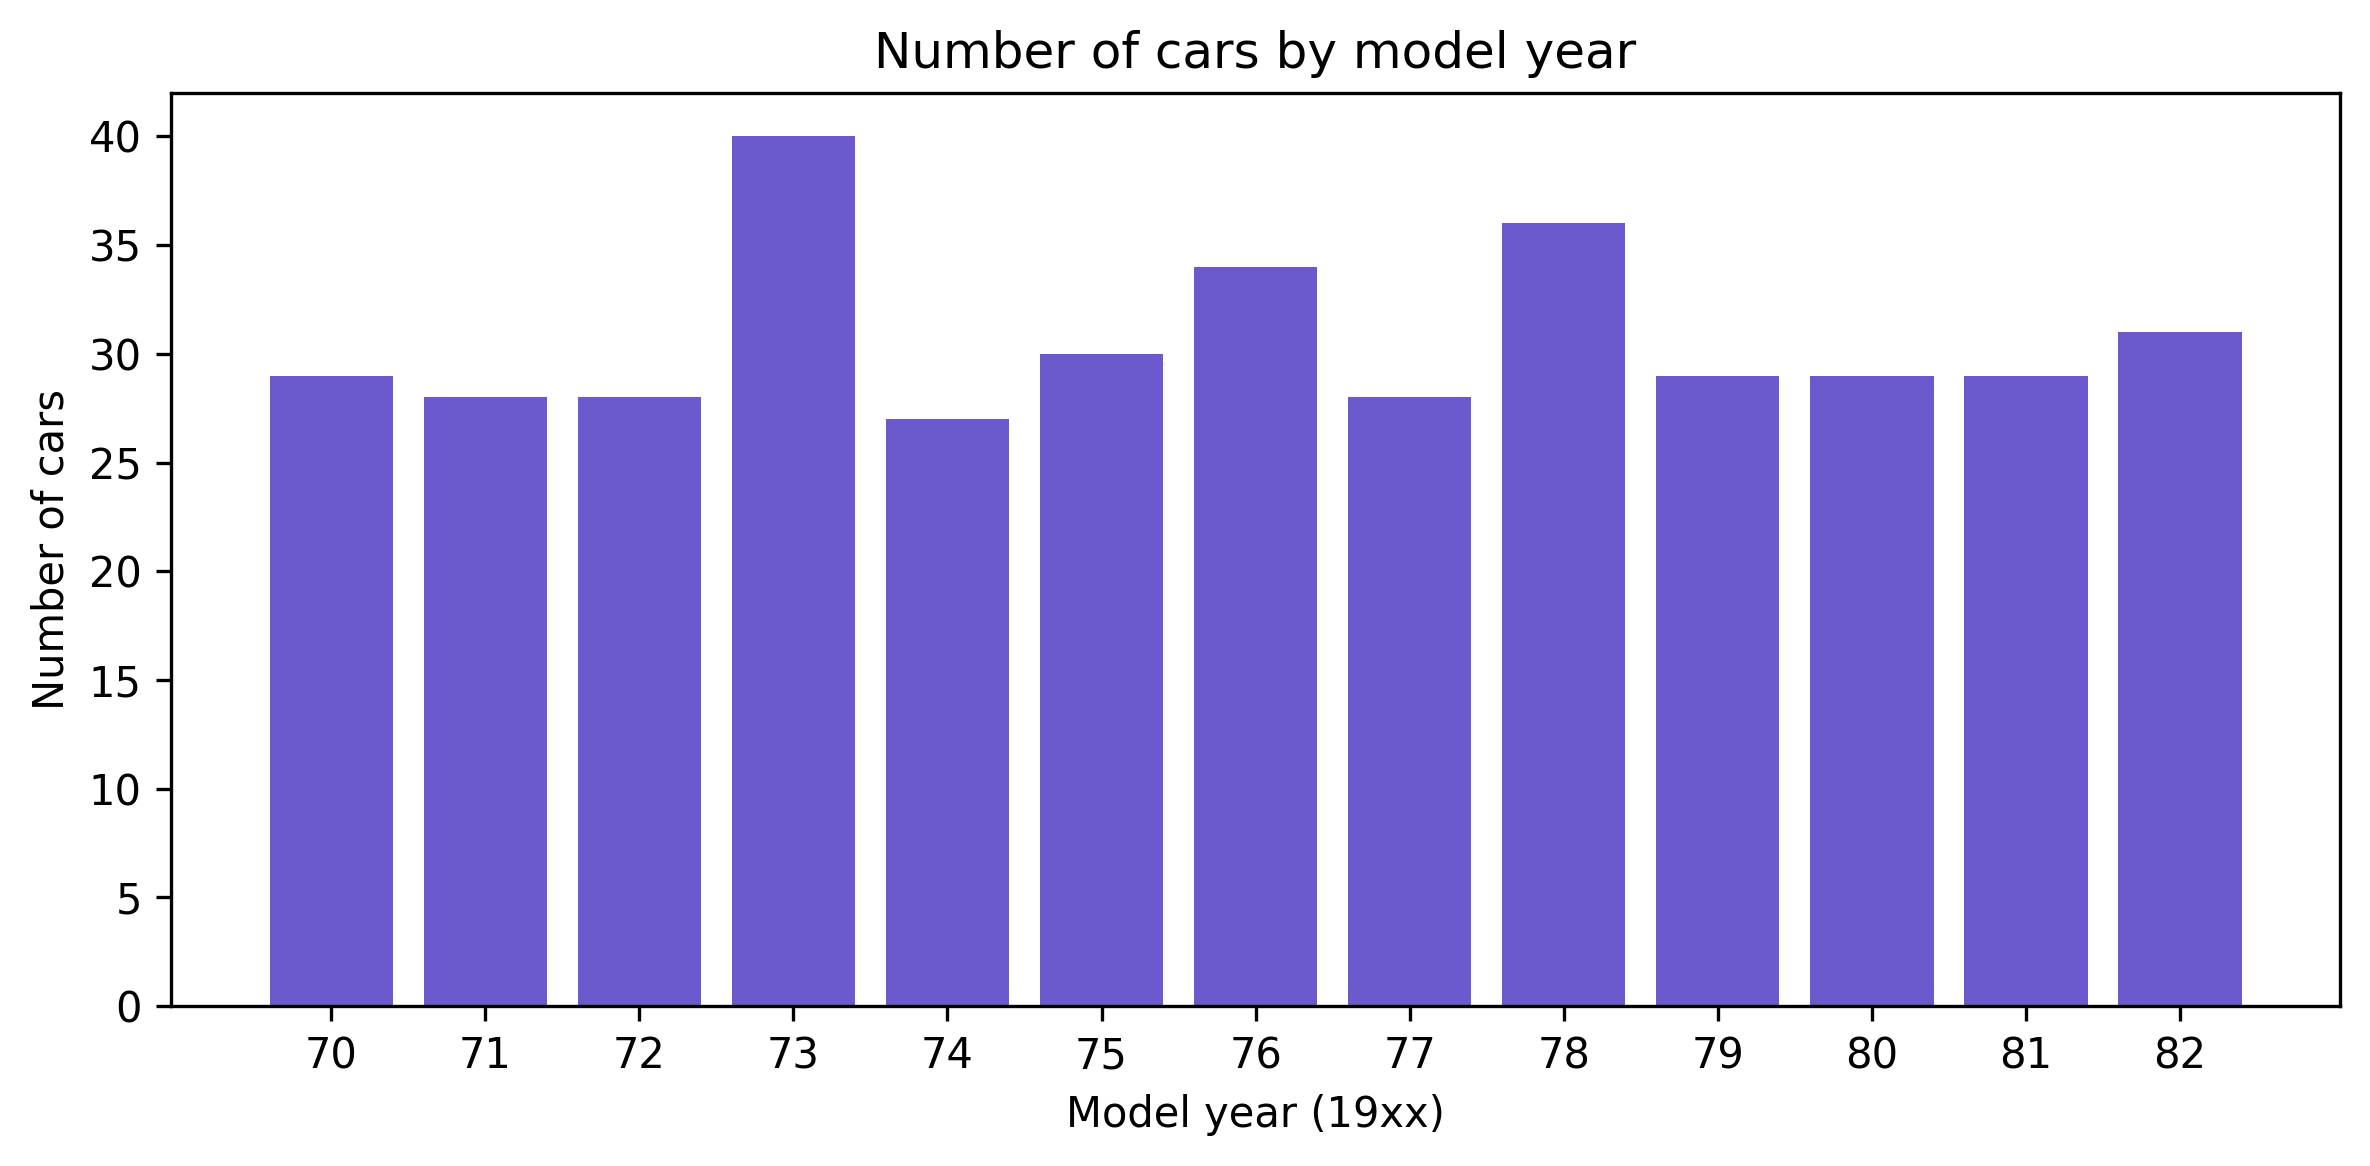

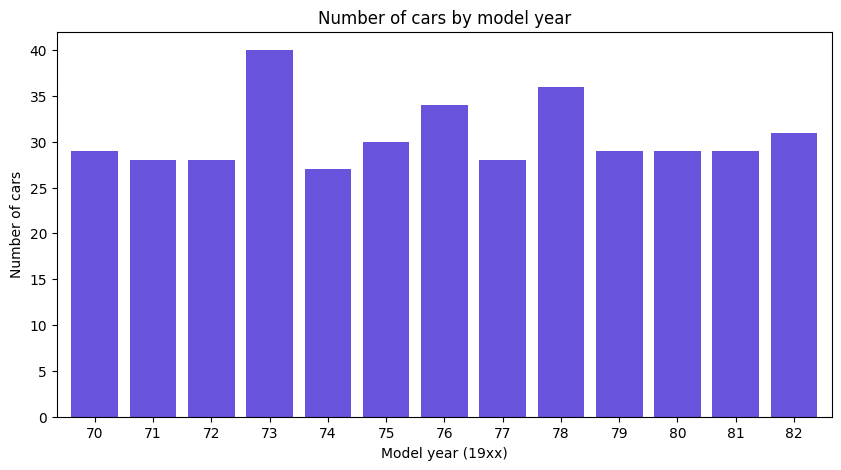

In [100]:
# Write your code here
plt.figure(figsize=(10, 5))
df['model_year'].value_counts().sort_index().plot(kind='bar', color='#6753dc', width=0.8, rot=0)
plt.title('Number of cars by model year')
plt.xlabel('Model year (19xx)')
plt.ylabel('Number of cars')
plt.show()

**✍️ Your observation** (write 1 or 2 lines):

*The number of cars sampled fluctuates across the years from 1970 to 1982, reaching a peak production/recording volume in 1973 with 40 cars, followed by another notable surge in 1978 with 36 vehicles.*

### M9 · Clusters in weight, horsepower and mpg
**Is there a clustering pattern among `weight`, `horsepower` and `mpg`?**
Create a **3-D scatter plot** of these three variables.

<details>
<summary>✅ What your chart should show</summary>

A 3-D cloud of points: **heavy, high-horsepower cars (the dark purple points) sit at the bottom with low mpg**, while **light, low-horsepower cars (the yellow points) sit near the top with high mpg**. Two loose groups are visible, which shows a clear pattern between the three variables.

</details>

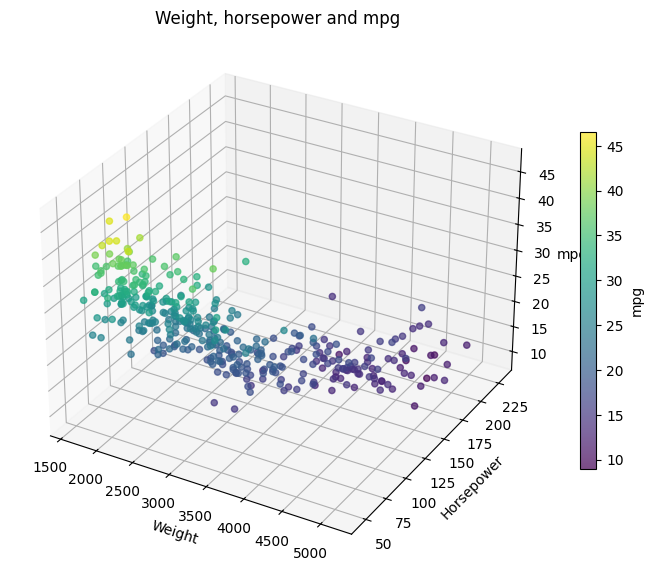

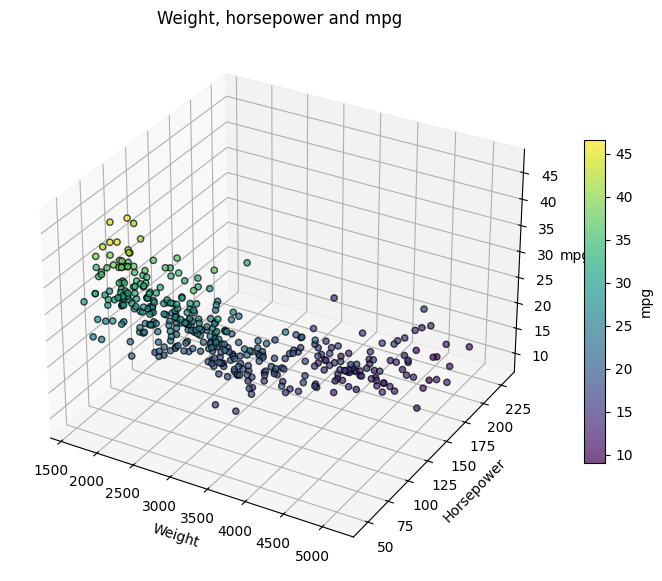

In [101]:
# Write your code here
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection='3d')
sc = ax.scatter(df['weight'], df['horsepower'], df['mpg'], c=df['mpg'], cmap='viridis', edgecolor='k', alpha=0.7)
ax.set_title('Weight, horsepower and mpg')
ax.set_xlabel('Weight')
ax.set_ylabel('Horsepower')
ax.set_zlabel('mpg')
fig.colorbar(sc, label='mpg', shrink=0.6, aspect=15)
plt.show()

**✍️ Your observation** (write 1 or 2 lines):

*The 3D visualization demonstrates that vehicles with lower weight and lower horsepower cluster together with high fuel efficiency (bright yellow/green points exceeding 35–45 mpg), whereas cars combining heavy weight and high horsepower drop significantly in fuel economy (dark purple points below 15 mpg)*

### M10 · Most fuel-efficient cars
**Which 10 cars have the best fuel efficiency?**
Plot a **horizontal bar chart** showing the top 10 `car_name`s with the highest `mpg`.

<details>
<summary>✅ What your chart should show</summary>

A horizontal bar chart of 10 cars, the longest bar at the top: mazda glc (46.6), honda civic 1500 gl (44.6), vw rabbit c (diesel) (44.3), vw pickup (44.0), vw dasher (diesel) (43.4), volkswagen rabbit custom diesel (43.1), vw rabbit (41.5), renault lecar deluxe (40.9), datsun 210 (40.8), datsun b210 gx (39.4).

</details>

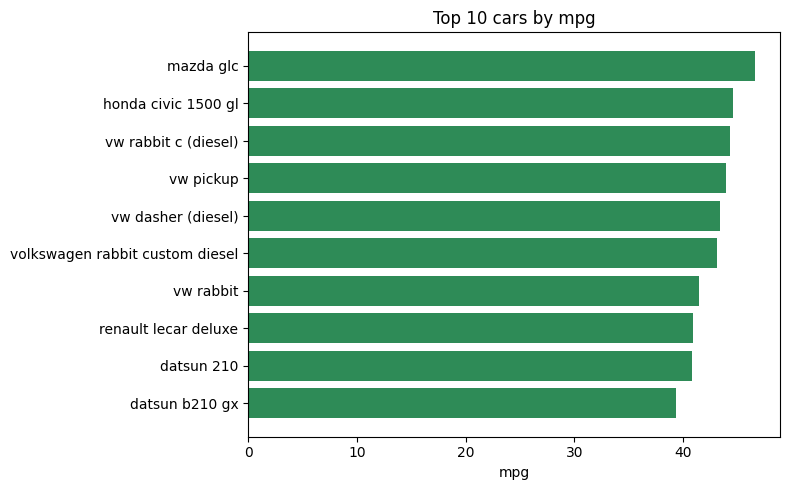

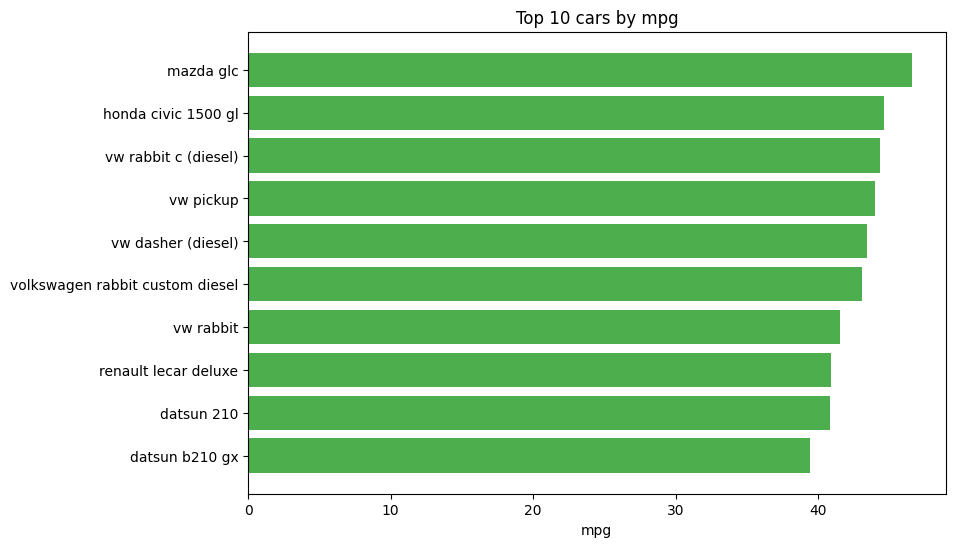

In [102]:
# Write your code here
plt.figure(figsize=(9, 6))
top10 = df.nlargest(10, 'mpg').sort_values('mpg')
plt.barh(top10['car_name'], top10['mpg'], color='#2ca02c', alpha=0.85)
plt.title('Top 10 cars by mpg')
plt.xlabel('mpg')
plt.show()

**✍️ Your observation** (write 1 or 2 lines):

*The top 10 most fuel-efficient cars in the dataset achieve between roughly 39 and 47 mpg, heavily dominated by lightweight economy models and efficient diesel/compact variants from manufacturers like Mazda, Honda, Volkswagen, and Datsun*

---
## Submission
Save the notebook as **`YourName_AutoMPG_CaseStudy.ipynb`**, run **Restart and Run All**, and submit it as instructed by your trainer (include `high_mpg_cars.csv` if asked).

**Reflect:** which question was the hardest? Which functions did you have to look up?